# Validation
In this notebook, we perform internal consistency checks and compare results to external metrics to validate our data.

In [39]:
import pandas as pd
import numpy as np
import geopandas as gpd
import math

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.transforms import ScaledTranslation
import seaborn as sns
from cmcrameri import cm

from molmass import Formula

import requests

# add main repo directory to path
import sys
import os
sys.path.append(os.path.abspath('..'))

# add submodules to path
sys.path.append('../submodules/gw-avail-and-comp')

# set up figure style in same way as gw-avail-and-comp repo
from project_utils import setup_figure_style, subscript_numbers, get_boundaries, project_crs
setup_figure_style()

# Load Data

In [40]:
# state geodataframe
st_df = get_boundaries('state')
st_df.drop(index=st_df[st_df['STUSPS']=='DC'].index, inplace=True)
st_df = st_df.sort_values(by='NAME').reset_index(drop=True)

In [41]:
# load market, demand, and price data
demand_path = '../data/inputs/sw1_demand.xlsx'

# market - collapse by end use category
market_df = pd.read_excel(demand_path, sheet_name = 'X1. Markets', na_values=['–'])
market_df = market_df.groupby(['byproduct', 'end_use_category'], as_index=False).agg({'pct_demand': lambda x: x.sum(skipna=False)})

# demand
bpd_df = pd.read_excel(demand_path, sheet_name = 'X2. BP x Domestic', na_values=['–'])
bpms_df = pd.read_excel(demand_path, sheet_name = 'X3. BP-Market x State', na_values=['–'])

# price
price_df = pd.read_excel(demand_path, sheet_name = 'X4. Pricing', na_values=['–'])

In [42]:
# load disaggregation proxies
proxy_path = '../data/inputs/sw2_disaggregation_proxies.xlsx'
proxy_file = pd.ExcelFile(proxy_path)
sheets_to_read = [sheet for sheet in proxy_file.sheet_names if sheet != "README"]
proxy_dict = {sheet : proxy_file.parse(sheet, header=3, usecols='B:E', nrows=48) for sheet in sheets_to_read}

# combine into single dataframe for validation
proxy_df = st_df[['STUSPS', 'geometry']].copy()
proxy_df.rename(columns={'STUSPS': 'State Alpha'}, inplace=True)
for proxy, df in proxy_dict.items():
    proxy_df = proxy_df.merge(df[['State Alpha', 'Percent of Total']], how='left', on='State Alpha')
    proxy_df.rename(columns={'Percent of Total': proxy}, inplace=True)


In [43]:
# load output demand results
results_df = pd.read_csv('../data/outputs/results.csv')

In [44]:
# load validation data
validation_path = '../data/inputs/sw3_validation.xlsx'
ib_market_df = pd.read_excel(validation_path, sheet_name= 'X1. Markets', na_values=['–'])
ib_demand_df = pd.read_excel(validation_path, sheet_name= 'X2. Demand', na_values=['–'], index_col=0)
ctv_proxy_df = pd.read_excel(validation_path, sheet_name= 'X3. Disaggregation Proxies', na_values=[''])

# add geometry to each district in ctv_proxy_df
geoms = []
for i, row in ctv_proxy_df.iterrows():
    district = row['District']
    if "," in district:
        states_in_district = district.split(', ')
    else:
        states_in_district = district.split(' and ')
    
    geom = st_df[st_df['NAME'].isin(states_in_district)]['geometry'].union_all()
    geoms.append(geom)

ctv_proxy_df = gpd.GeoDataFrame(ctv_proxy_df, geometry=geoms, crs=project_crs)

# Internal Consistency Checks

## Confirm End-Use Category Shares Sum to 100%
For each byproduct, we ensure that the sum of end-use category market shares employed sums to 100%.

In [45]:
# iterate through byproducts in market_df and sum total pct_demand
for bp in market_df['byproduct'].unique():
    print(f'========== {bp} ==========')
    total_pct_demand = market_df.loc[market_df['byproduct'] == bp, 'pct_demand'].sum()
    print(f'\tSum of Market Shares: {total_pct_demand:.2%}')
    if not math.isclose(total_pct_demand, 1.0, rel_tol=0.01): # allow for 1% difference to account for rounding errors
        print(market_df.loc[market_df['byproduct'] == bp, ['end_use_category', 'pct_demand']])

========== BaSO4 ==========
	Sum of Market Shares: 100.00%
========== Br ==========
	Sum of Market Shares: 100.00%
========== Ca(OH)2 ==========
	Sum of Market Shares: 100.00%
========== CaCO3 ==========
	Sum of Market Shares: 100.00%
========== CaSO4 ==========
	Sum of Market Shares: 100.00%
========== HCl ==========
	Sum of Market Shares: 100.00%
========== K2O ==========
	Sum of Market Shares: 100.00%
========== Li ==========
	Sum of Market Shares: 100.00%
========== Mg(OH)2 ==========
	Sum of Market Shares: 100.00%
========== MgCl2 ==========
	Sum of Market Shares: 100.00%
========== MgSO4 ==========
	Sum of Market Shares: 100.00%
========== Na2CO3 ==========
	Sum of Market Shares: 100.00%
========== NaCl ==========
	Sum of Market Shares: 100.00%
========== NaOH ==========
	Sum of Market Shares: 100.00%
========== P2O5 ==========
	Sum of Market Shares: 100.00%
========== SrSO4 ==========
	Sum of Market Shares: 100.00%


## Confirm Sum of State-Level Demand = Domestic Demand
For byproducts for which state-level demand was disaggregated from a total domestic value, we ensure that the sum of state-level demands in a given year across all states and markets is equal to the total domestic byproduct demand for that year.

For byproducts for which state-level demand was taken directly from a source, and withheld quantities were allocated among remaining states, we ensure that the sum of state-level demands in a given year and market is equal to the total reported demand for that byproduct market.

In [46]:
# iterate through byproducts in bpd_df and compare domestic demand to sum of estimated state level demand across all markets
for i, row in bpd_df.iterrows():
    bp = row['byproduct']
    print(f'========== {bp} ==========')
    for year in range(2021, 2026):
        domestic_demand = row[f'demand_{year}_kt']
        try:
            pct_other = market_df[(market_df['byproduct']==bp) & (market_df['end_use_category']=='Other')]['pct_demand'].values[0]
        except IndexError:
            pct_other = 0
        domestic_demand = domestic_demand * (1 - pct_other) # remove "Other" demand from domestic demand to compare to state-level demand
        state_demand = results_df[(results_df['byproduct'] == bp) & (results_df['year'] == year)].copy()
        sum_demand = state_demand['demand_kt'].sum()
        is_close = math.isclose(domestic_demand, sum_demand, rel_tol=0.05) # 5% tolerance to account for rounding errors
        print(f'\t{year}:\tDomestic: {domestic_demand:.2f} kt, Sum of State: {sum_demand:.2f} kt, Close: {is_close}{f' !!!!!' if not is_close else ""}')


========== BaSO4 ==========
	2021:	Domestic: 2810.66 kt, Sum of State: 2790.92 kt, Close: True
	2022:	Domestic: 3816.65 kt, Sum of State: 3789.85 kt, Close: True
	2023:	Domestic: 3598.71 kt, Sum of State: 3573.43 kt, Close: True
	2024:	Domestic: 3655.21 kt, Sum of State: 3629.54 kt, Close: True
	2025:	Domestic: 3701.85 kt, Sum of State: 3675.85 kt, Close: True
========== Br ==========
	2021:	Domestic: 200.30 kt, Sum of State: 199.06 kt, Close: True
	2022:	Domestic: 220.10 kt, Sum of State: 218.74 kt, Close: True
	2023:	Domestic: 206.90 kt, Sum of State: 205.62 kt, Close: True
	2024:	Domestic: 219.50 kt, Sum of State: 218.14 kt, Close: True
	2025:	Domestic: 206.00 kt, Sum of State: 204.72 kt, Close: True
========== Ca(OH)2 ==========
	2021:	Domestic: 2335.45 kt, Sum of State: 2327.73 kt, Close: True
	2022:	Domestic: 2363.59 kt, Sum of State: 2355.77 kt, Close: True
	2023:	Domestic: 2222.90 kt, Sum of State: 2215.55 kt, Close: True
	2024:	Domestic: 2110.34 kt, Sum of State: 2103.37 kt, C

In [47]:
# iterate through byproduct markets in bpms_df and compare domestic demand to sum of estimated state level demand
pd.set_option('future.no_silent_downcasting', True)
for bp in bpms_df['byproduct'].unique():
    print(f'========== {bp} ==========')
    for market in bpms_df[bpms_df['byproduct'] == bp]['end_use_category'].unique():
        print(f'\tMarket: {market}')
        for year in range(2021, 2026):
            # get the state level demand data from bpms_df for this byproduct, market, and year
            original_demand_data = bpms_df[(bpms_df['byproduct'] == bp) & (bpms_df['end_use_category'] == market)][['state', f'demand_{year}_kt']].copy()
            # drop states outside of conus
            original_demand_data = original_demand_data[original_demand_data['state'].isin(st_df['NAME'].tolist() + ['Total Withheld'])][f'demand_{year}_kt'].copy()

            # get domestic demand vs sum of states
            domestic_demand = original_demand_data.replace("W", np.nan).sum()
            state_demand = results_df[(results_df['byproduct'] == bp) & (results_df['end_use_category'] == market) & (results_df['year'] == year)].copy()
            sum_demand = state_demand['demand_kt'].sum()
            is_close = math.isclose(domestic_demand, sum_demand, rel_tol=0.05) # 5% tolerance to account for rounding errors
            print(f'\t{year}:\tDomestic: {domestic_demand:.2f} kt, Sum of State: {sum_demand:.2f} kt, Close: {is_close}{f' !!!!!' if not is_close else ""}')


========== CaCO3 ==========
	Market: Cement Manufacturing
	2021:	Domestic: 109729.00 kt, Sum of State: 109729.00 kt, Close: True
	2022:	Domestic: 109220.00 kt, Sum of State: 109220.00 kt, Close: True
	2023:	Domestic: 109552.00 kt, Sum of State: 109552.00 kt, Close: True
	2024:	Domestic: 108425.58 kt, Sum of State: 108425.58 kt, Close: True
	2025:	Domestic: 108425.58 kt, Sum of State: 108425.58 kt, Close: True
	Market: Lime Manufacturing
	2021:	Domestic: 40673.00 kt, Sum of State: 40673.00 kt, Close: True
	2022:	Domestic: 40716.00 kt, Sum of State: 40716.00 kt, Close: True
	2023:	Domestic: 33037.00 kt, Sum of State: 33037.00 kt, Close: True
	2024:	Domestic: 32034.83 kt, Sum of State: 32034.83 kt, Close: True
	2025:	Domestic: 32034.83 kt, Sum of State: 32034.83 kt, Close: True
========== MgCl2 ==========
	Market: Deicing and Dust Control
	2021:	Domestic: 168.85 kt, Sum of State: 168.85 kt, Close: True
	2022:	Domestic: 163.64 kt, Sum of State: 163.64 kt, Close: True
	2023:	Domestic: 90.30

## Confirm Disaggregation Proxies Sum to 100%
For each disaggregation proxy, we ensure that the state fractions sum to 100%.

In [48]:
for proxy in proxy_df.columns[2:]:
    sum_fracs = proxy_df[proxy].sum()
    is_close = math.isclose(sum_fracs, 1.0, rel_tol=0.05) # 5% tolerance to account for rounding errors
    print(f'{proxy:<40}: {sum_fracs:.2f}{f' (!!!!!)' if not is_close else ""}')

cement_production                       : 1.00
lime_facilities                         : 1.00
glass_emissions                         : 1.00
gypsum_facilities                       : 1.00
steel_pickling_facilities               : 1.00
pulp_and_paper_facilities               : 1.00
lithium_battery_capacity                : 1.00
cosmetics_employment                    : 0.98
org_chemical_employment                 : 0.95
pharma_employment                       : 1.00
phosphoric_acid_facilities              : 1.00
chemical_employment                     : 1.00
manufacturing_employment                : 0.98
industrial_water_use                    : 1.00
public_supply_water_use                 : 1.00
wwtp_flow                               : 1.00
road_salts_application                  : 1.00
construction_spending                   : 0.99
oil_and_gas_wells                       : 0.99
flue_gas_desulfurization                : 1.00
potash_fertilizer_consumption           : 1.00
crop_acreage 

# External Value Benchmarking

## Major End-Use Markets

In [53]:
ib_market_df

,byproduct,end_use_category,Assigned,Benchmark
0,Br,Miscellaneous Chemical Manufacturing,0.589456,0.510907
1,Br,Oil and Gas Drilling,0.126312,0.284254
2,Br,Organic Chemical Manufacturing,0.105321,0.000000
3,Br,Pharmaceutical Manufacturing,0.094703,0.000000
4,Br,Industrial Water Treatment,0.084208,0.056010
5,Br,Other,0.000000,0.148830


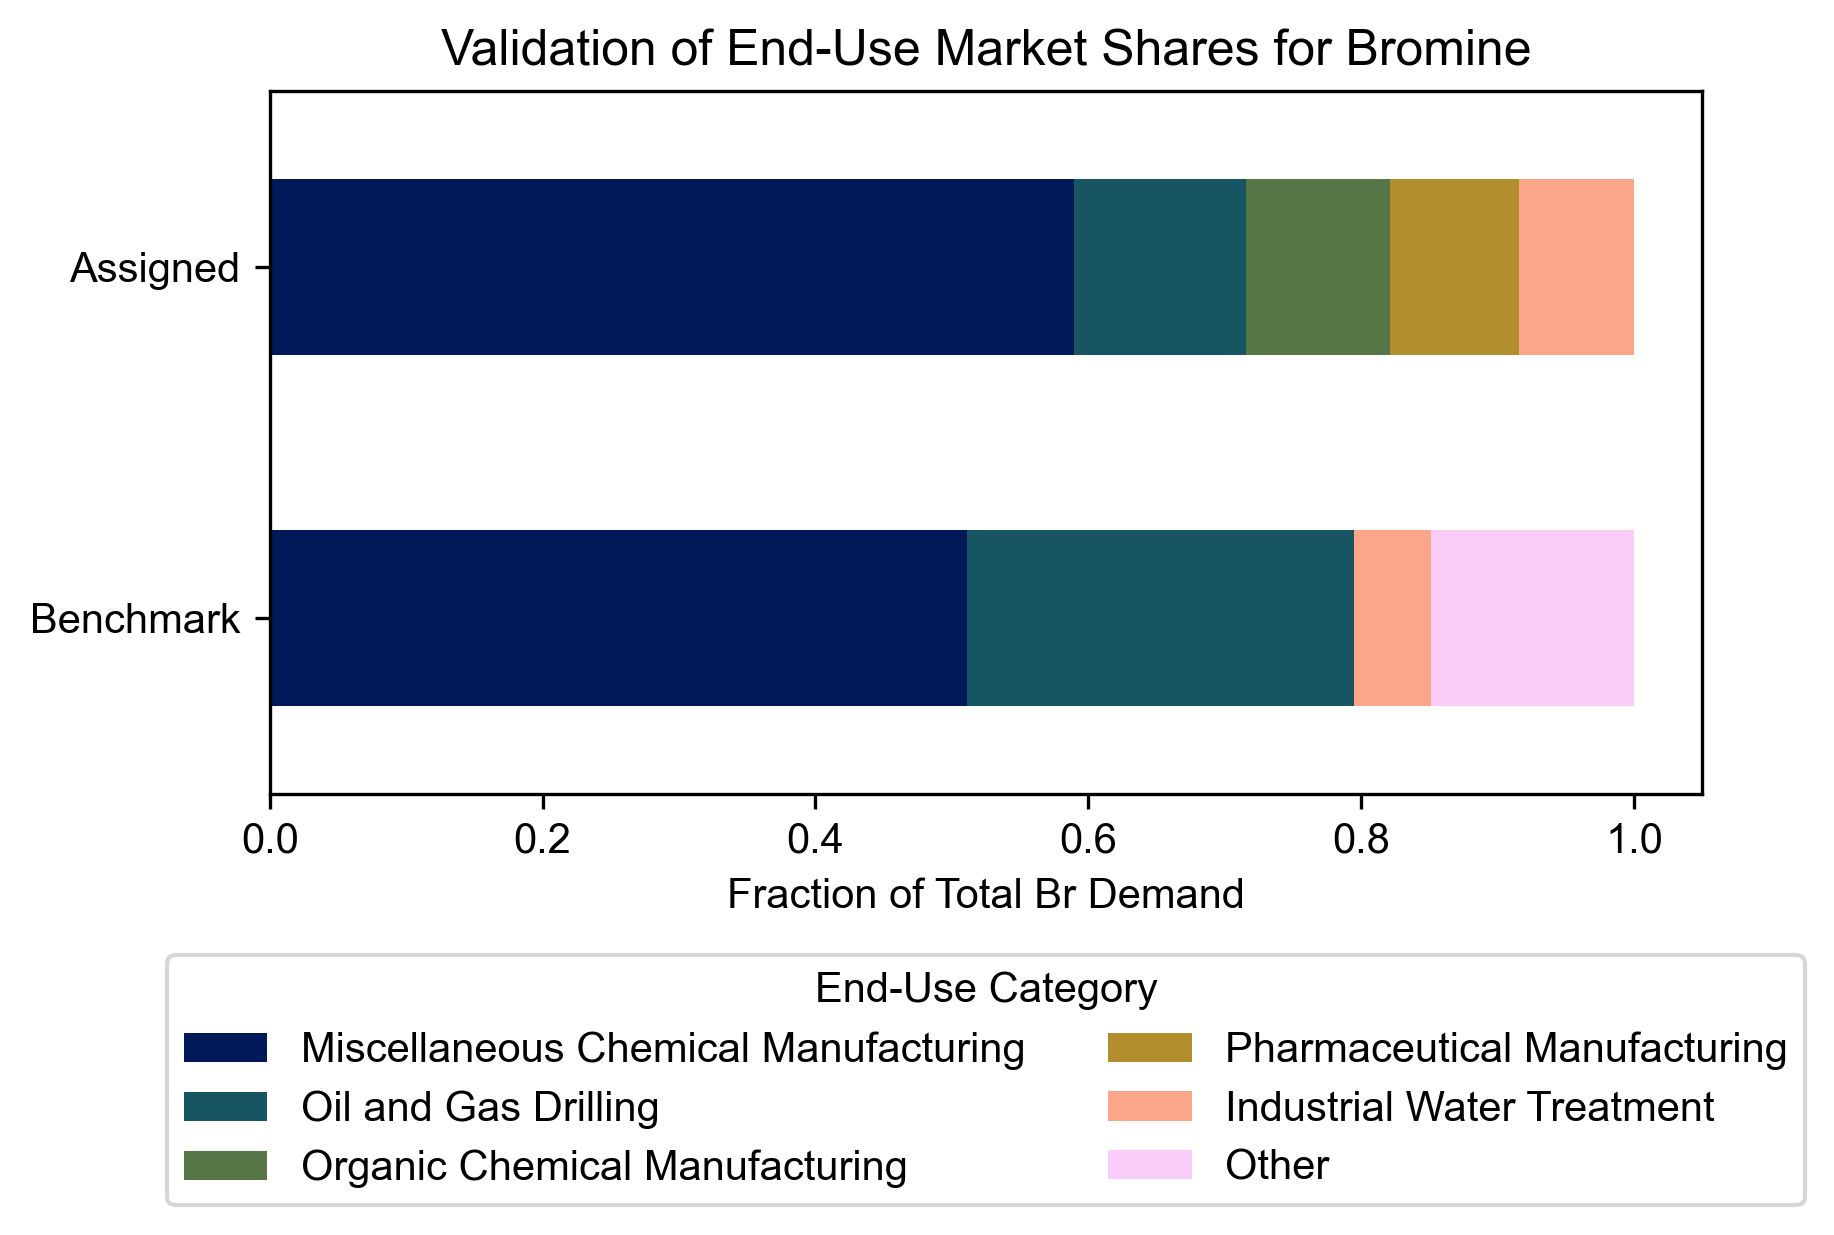

In [60]:
fig, ax = plt.subplots( figsize=(6, 4), layout='constrained')
if ib_market_df.index.name != 'end_use_category':
    ib_market_df.set_index('end_use_category', inplace=True)
    ib_market_df.drop(columns=['byproduct'], inplace=True)

# plot horizontal stacked bar chart of market shares for this byproduct across tiers
plot_data = ib_market_df.T
plot_data = plot_data.loc[plot_data.sum(axis=1).sort_values(ascending=False).index]
plot_data.plot(kind='barh', stacked=True, ax=ax, colormap=cm.batlow)

ax.set_title("Validation of End-Use Market Shares for Bromine")
ax.invert_yaxis()
ax.set_xlabel(f'Fraction of Total {subscript_numbers(bp)} Demand')
ax.legend(title='End-Use Category', loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

fig.savefig('../figures/market_shares.pdf', bbox_inches='tight')

## Domestic Byproduct Demand

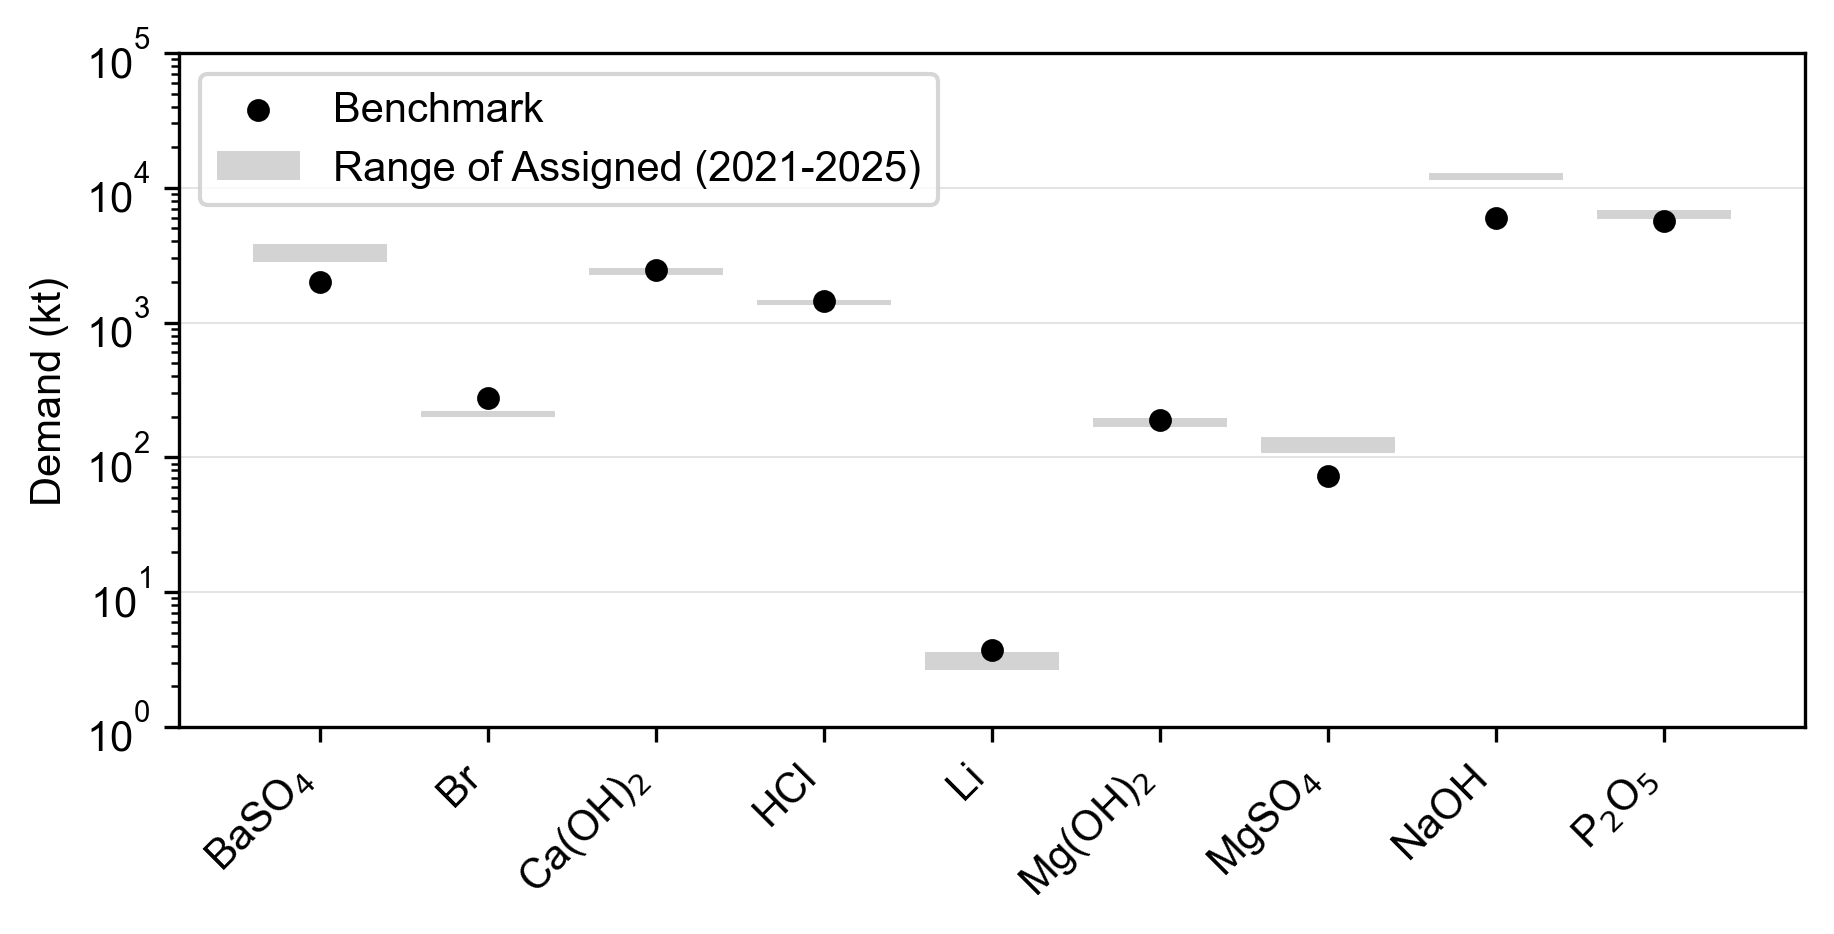

In [80]:
fig, ax = plt.subplots(figsize=(6,3), layout='constrained')
for i, bp in enumerate(ib_demand_df.index):
    # get demand data for this byproduct across five years
    assigned_demand = bpd_df[bpd_df['byproduct'] == bp].copy().set_index('byproduct').values

    # get benchmark demand for this byproduct and known comparison (if applicable)
    benchmark_demand = ib_demand_df.loc[bp, 'benchmark_demand_kt']

    # plot range of assigned demand across five years
    min_demand = assigned_demand.min()
    max_demand = assigned_demand.max()
    ax.bar(i, max_demand - min_demand, bottom=min_demand, width=0.8, color='lightgrey', edgecolor='none', linewidth=0.5,
           label='Range of Assigned (2021-2025)' if i == 0 else None)

    # plot benchmark demand for this byproduct
    ax.scatter(i, benchmark_demand, marker='o', color='black', s=20, label='Benchmark' if i == 0 else None)

# format axes
ax.set_yscale('log')
ax.set_ylabel('Demand (kt)')

ax.set_ylim([1e0, 1e5])
ax.set_xticks(range(len(ib_demand_df.index)))
ax.set_xticklabels([subscript_numbers(bp) for bp in ib_demand_df.index], rotation=45, ha='right')
ax.grid(axis='y', which='major', linestyle='-', color='grey', linewidth=0.1)

ax.legend(loc='upper left', frameon=True)

fig.savefig('../figures/demand_validation.pdf', bbox_inches='tight')

## Disaggregation Proxies

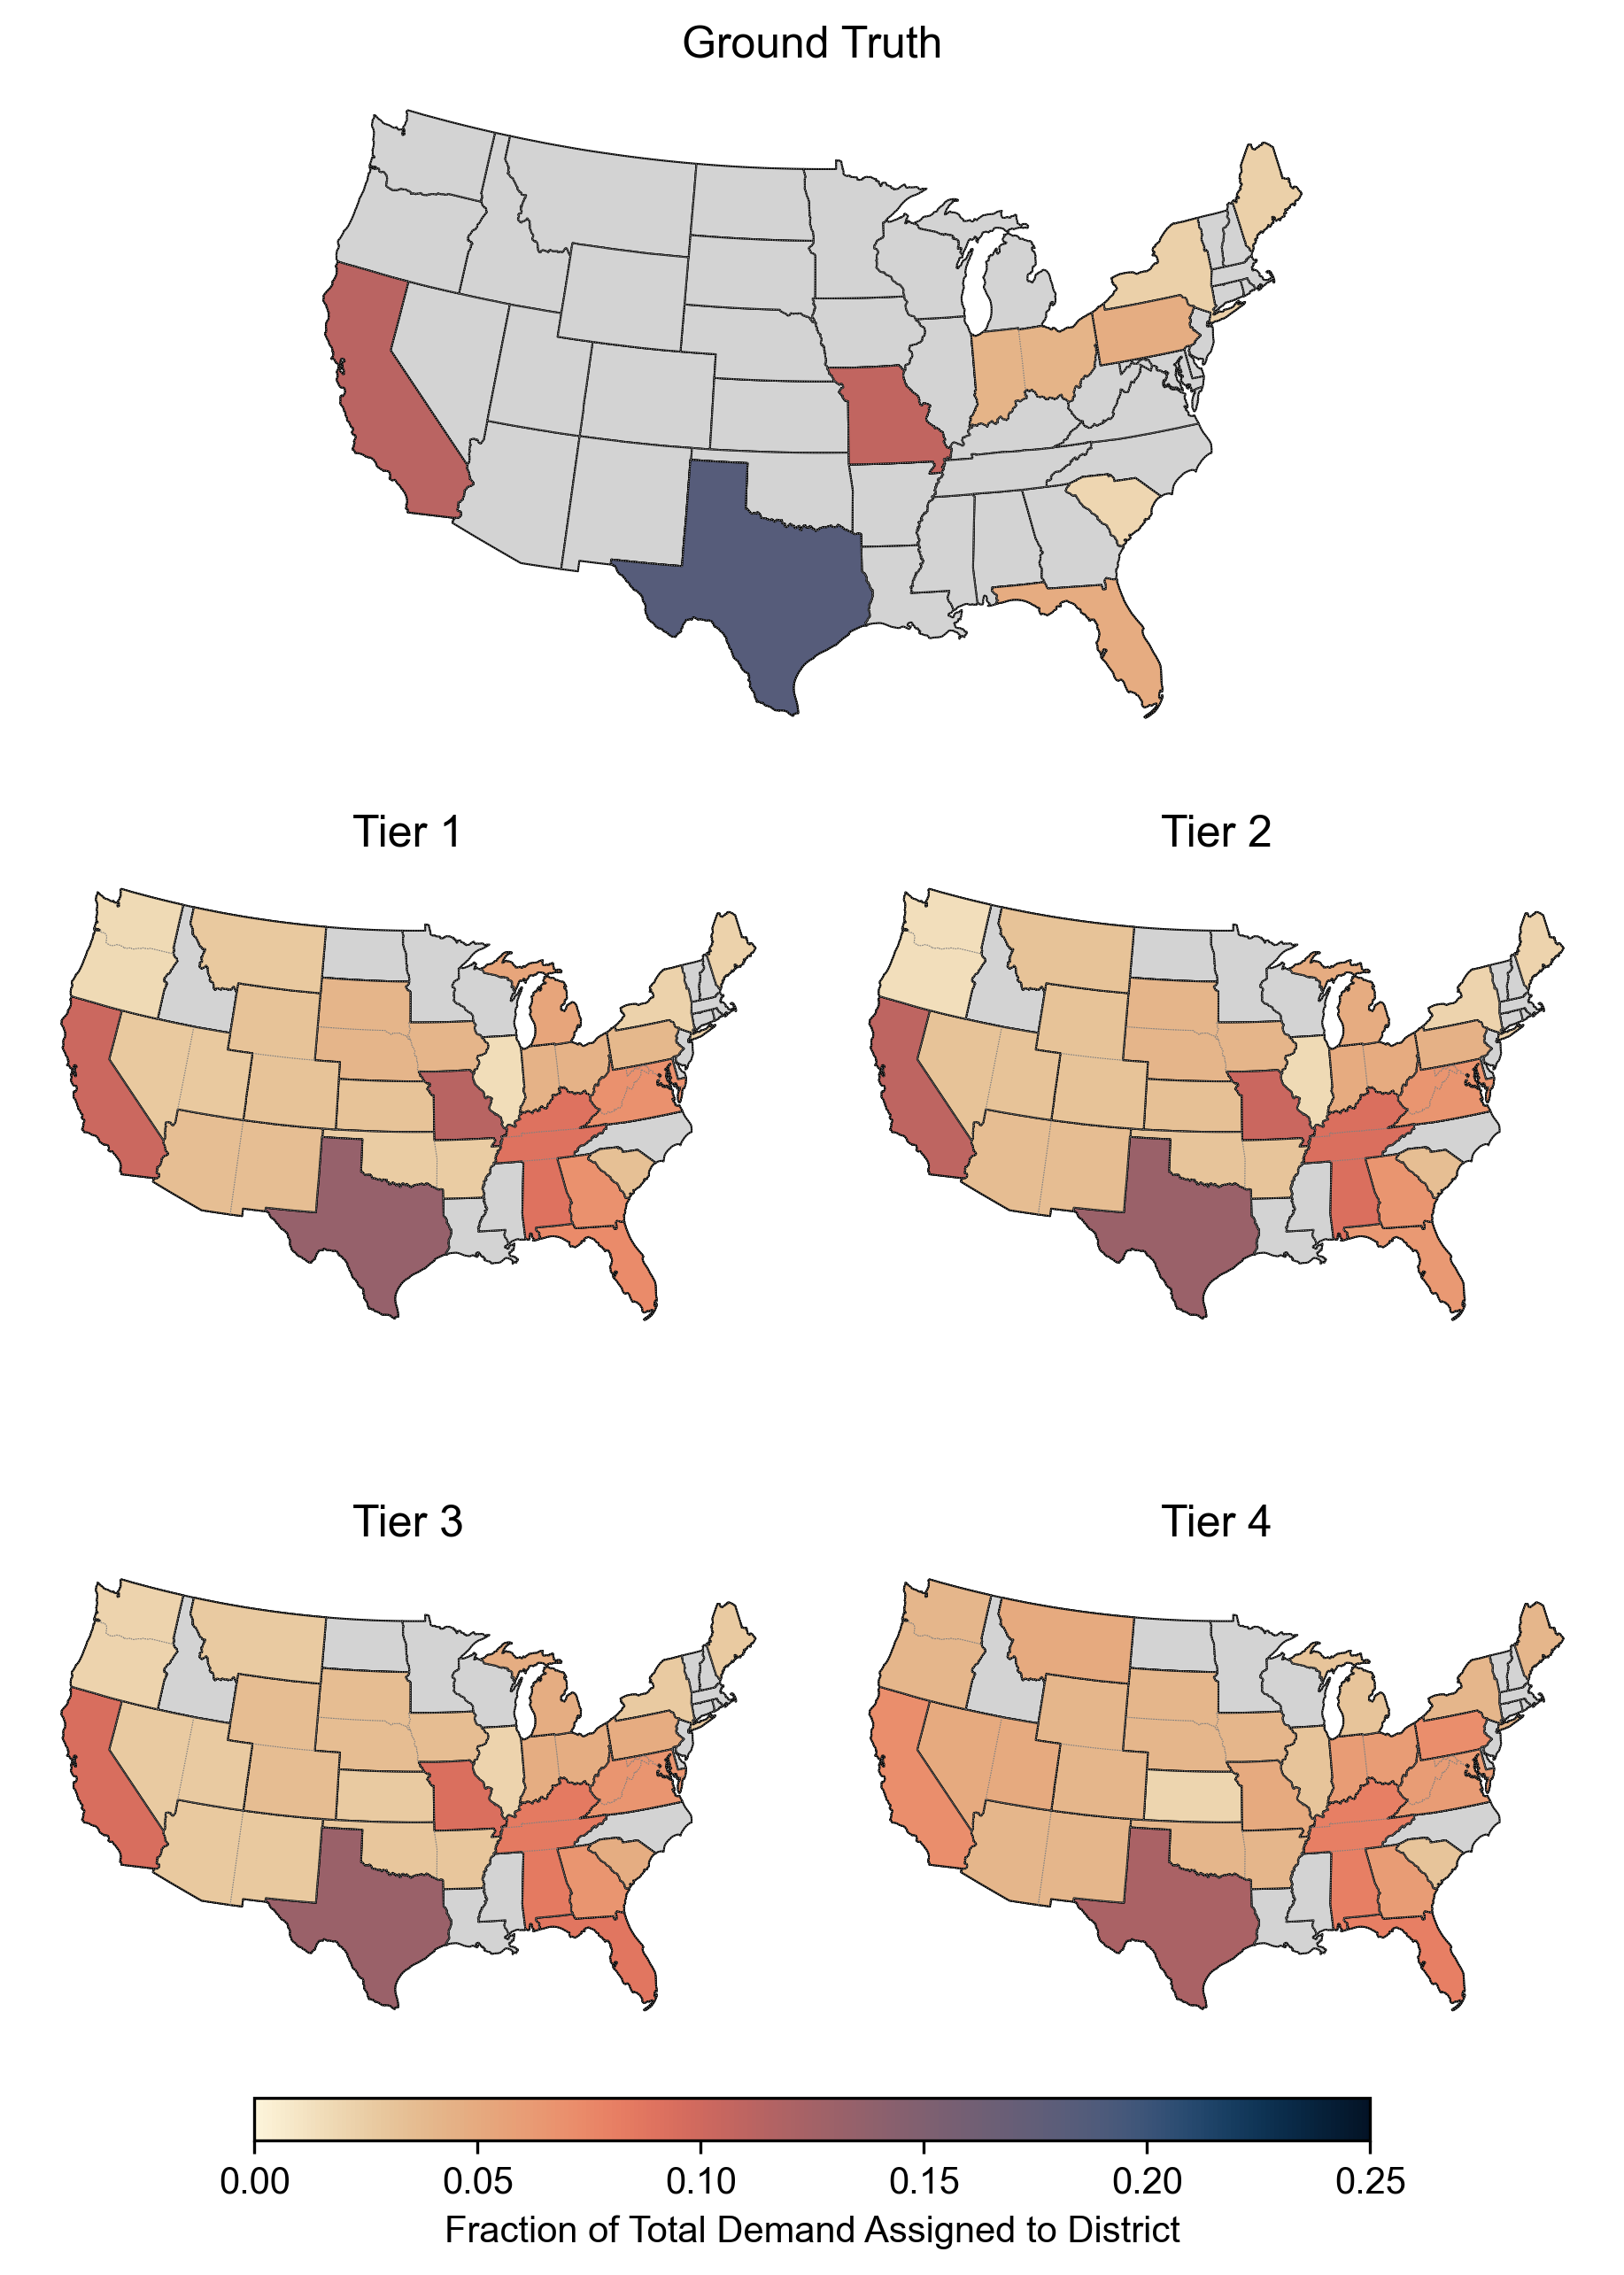

In [81]:
# plot map of proxy values across all tiers for each district in ctv_proxy_df
fig, axs = plt.subplot_mosaic([
    ['A', 'A'],
    ['B', 'C'],
    ['D', 'E']
], figsize=(6, 8), layout='constrained')

tier_to_panel_dict = {
    'Ground Truth': 'A',
    'Tier 1': 'B',
    'Tier 2': 'C',
    'Tier 3': 'D',
    'Tier 4': 'E'
}

norm = Normalize(vmin=0, vmax=0.25)

for tier, panel in tier_to_panel_dict.items():
    ax = axs[panel]
    ax.axis('off')

    # base map of all states
    st_df.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.5)

    # plot of proxy values by district
    ctv_proxy_df.plot(ax=ax, column=tier, cmap=cm.lipari_r, norm=norm, edgecolor='black', linewidth=0.5)

    # overlay with state boundaries
    st_df.plot(ax=ax, color='none', edgecolor='grey', linestyle=':', linewidth=0.25)
    ax.set_title(tier)

# add a colorbar to the bottom
cbar_ax = fig.add_axes([0.15, 0, 0.7, 0.02])
sm = plt.cm.ScalarMappable(cmap=cm.lipari_r, norm=norm)
sm._A = []
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', label='Fraction of Total Demand Assigned to District')